In [2]:
import pandas as pd, numpy as np, glob
import matplotlib.pyplot as plt, seaborn as sns

path = glob.glob('/kaggle/input/**/housing.csv', recursive=True)[0]
df = pd.read_csv(path)

print("Shape:", df.shape)
print("\nColumns and data types:\n", df.dtypes)
print("\nFirst 5 rows:\n", df.head())

miss = df.isnull().sum()
print("\nMissing values:\n", miss[miss > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("\nStatistical summary:\n", df.describe().round(2))

Shape: (20640, 10)

Columns and data types:
 longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object

First 5 rows:
    longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0   

Prices at the 500001 cap: 992 rows

Houses per location category:
 ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

Average price by location:
 ocean_proximity
ISLAND        380440.0
NEAR BAY      259212.0
NEAR OCEAN    249434.0
<1H OCEAN     240084.0
INLAND        124805.0
Name: median_house_value, dtype: float64

Correlation of each feature with price:
 median_income         0.688
total_rooms           0.134
housing_median_age    0.106
households            0.066
total_bedrooms        0.050
population           -0.025
longitude            -0.046
latitude             -0.144
Name: median_house_value, dtype: float64


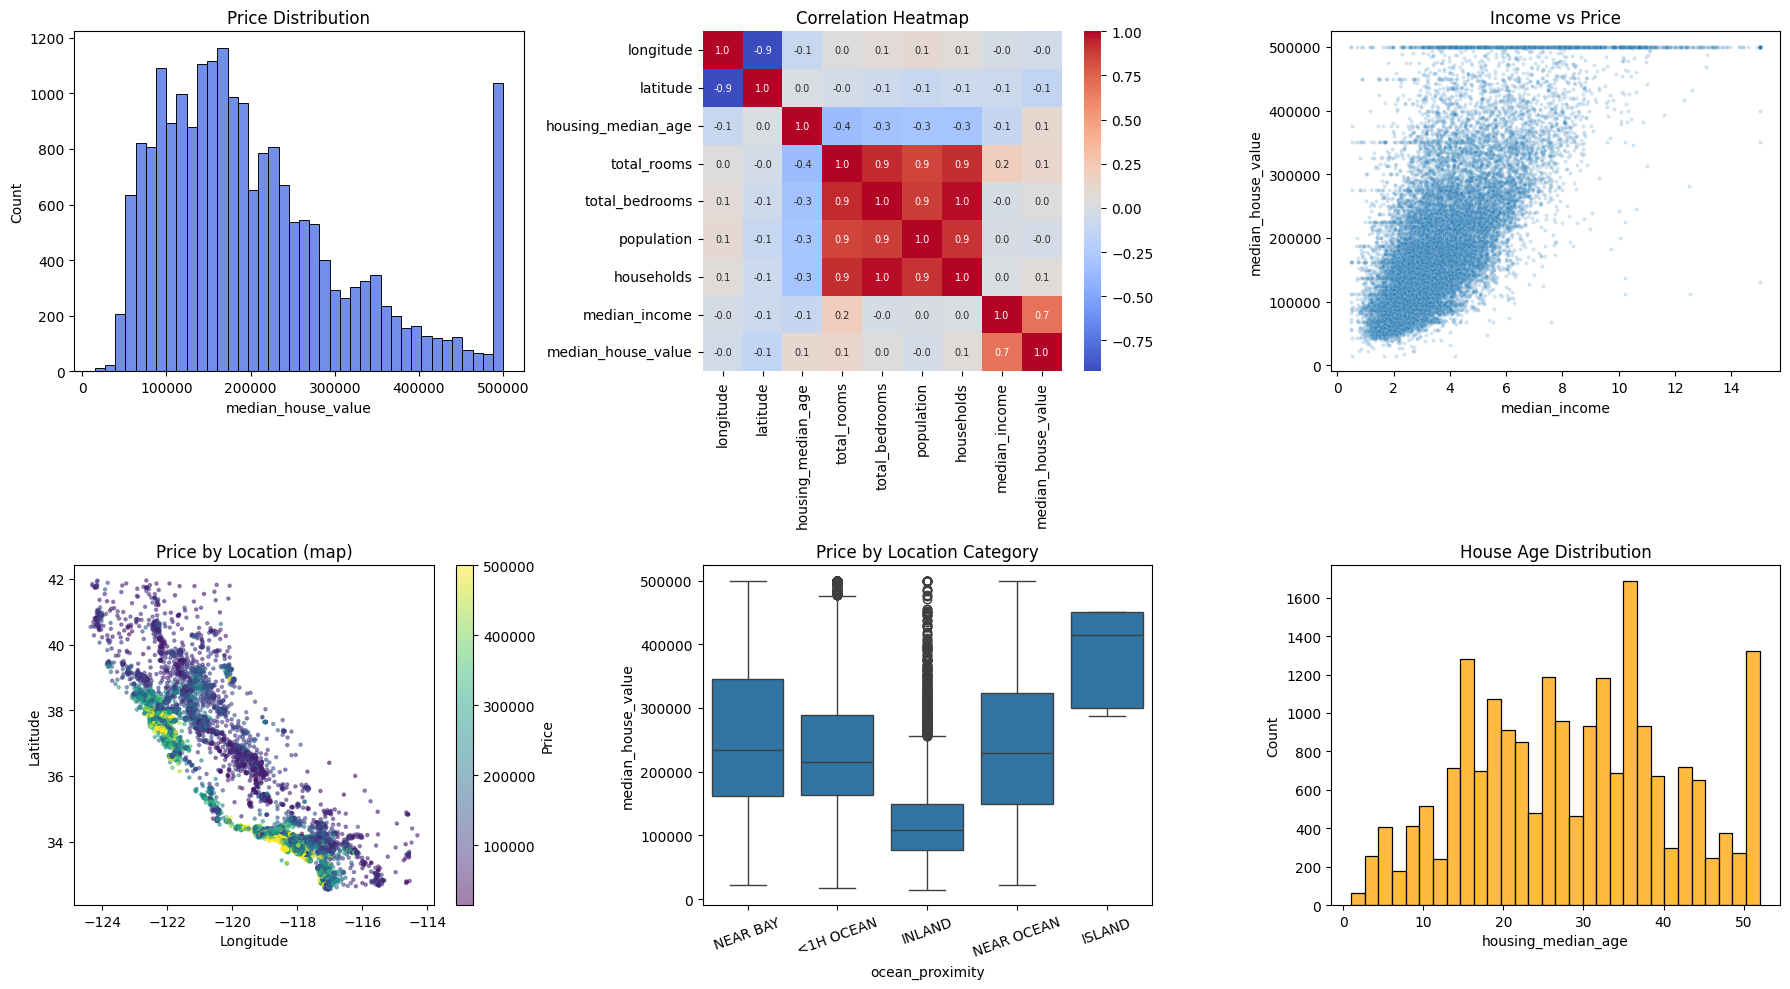

In [3]:
target = 'median_house_value'

# Text findings
print("Prices at the 500001 cap:", (df[target] >= 500000).sum(), "rows")
print("\nHouses per location category:\n", df['ocean_proximity'].value_counts())
print("\nAverage price by location:\n",
      df.groupby('ocean_proximity')[target].mean().round(0).sort_values(ascending=False))

corr = df.drop(columns='ocean_proximity').corr()[target].drop(target).sort_values(ascending=False)
print("\nCorrelation of each feature with price:\n", corr.round(3))

# Charts
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.histplot(df[target], bins=40, color='royalblue', ax=axes[0, 0])
axes[0, 0].set_title('Price Distribution')

sns.heatmap(df.drop(columns='ocean_proximity').corr(), cmap='coolwarm', annot=True,
            fmt='.1f', annot_kws={'size': 7}, ax=axes[0, 1])
axes[0, 1].set_title('Correlation Heatmap')

sns.scatterplot(x='median_income', y=target, data=df, alpha=0.2, s=8, ax=axes[0, 2])
axes[0, 2].set_title('Income vs Price')

sc = axes[1, 0].scatter(df['longitude'], df['latitude'], c=df[target], cmap='viridis', s=5, alpha=0.5)
plt.colorbar(sc, ax=axes[1, 0], label='Price')
axes[1, 0].set_title('Price by Location (map)')
axes[1, 0].set_xlabel('Longitude'); axes[1, 0].set_ylabel('Latitude')

sns.boxplot(x='ocean_proximity', y=target, data=df, ax=axes[1, 1])
axes[1, 1].set_title('Price by Location Category')
axes[1, 1].tick_params(axis='x', rotation=20)

sns.histplot(df['housing_median_age'], bins=30, color='orange', ax=axes[1, 2])
axes[1, 2].set_title('House Age Distribution')

plt.tight_layout(); plt.show()

Correlation of new features with price:
 rooms_per_household         0.152
bedrooms_per_room          -0.233
population_per_household   -0.024
Name: median_house_value, dtype: float64

Skewness of key columns:
 median_house_value    0.98
median_income         1.65
total_rooms           4.15
population            4.94
dtype: float64

Outlier check (max values):
 rooms_per_household          141.9
bedrooms_per_room              2.8
population_per_household    1243.3
dtype: float64
Rows with rooms_per_household > 20: 69
Rows with population_per_household > 10: 37

Average price by income group:
 income_group
Very Low     118403.0
Low          157030.0
Medium       193890.0
High         230029.0
Very High    334991.0
Name: median_house_value, dtype: float64

Average price by house age group:
 age_group
0-10     200263.0
10-20    191182.0
20-30    206802.0
30-40    206662.0
40+      228965.0
Name: median_house_value, dtype: float64


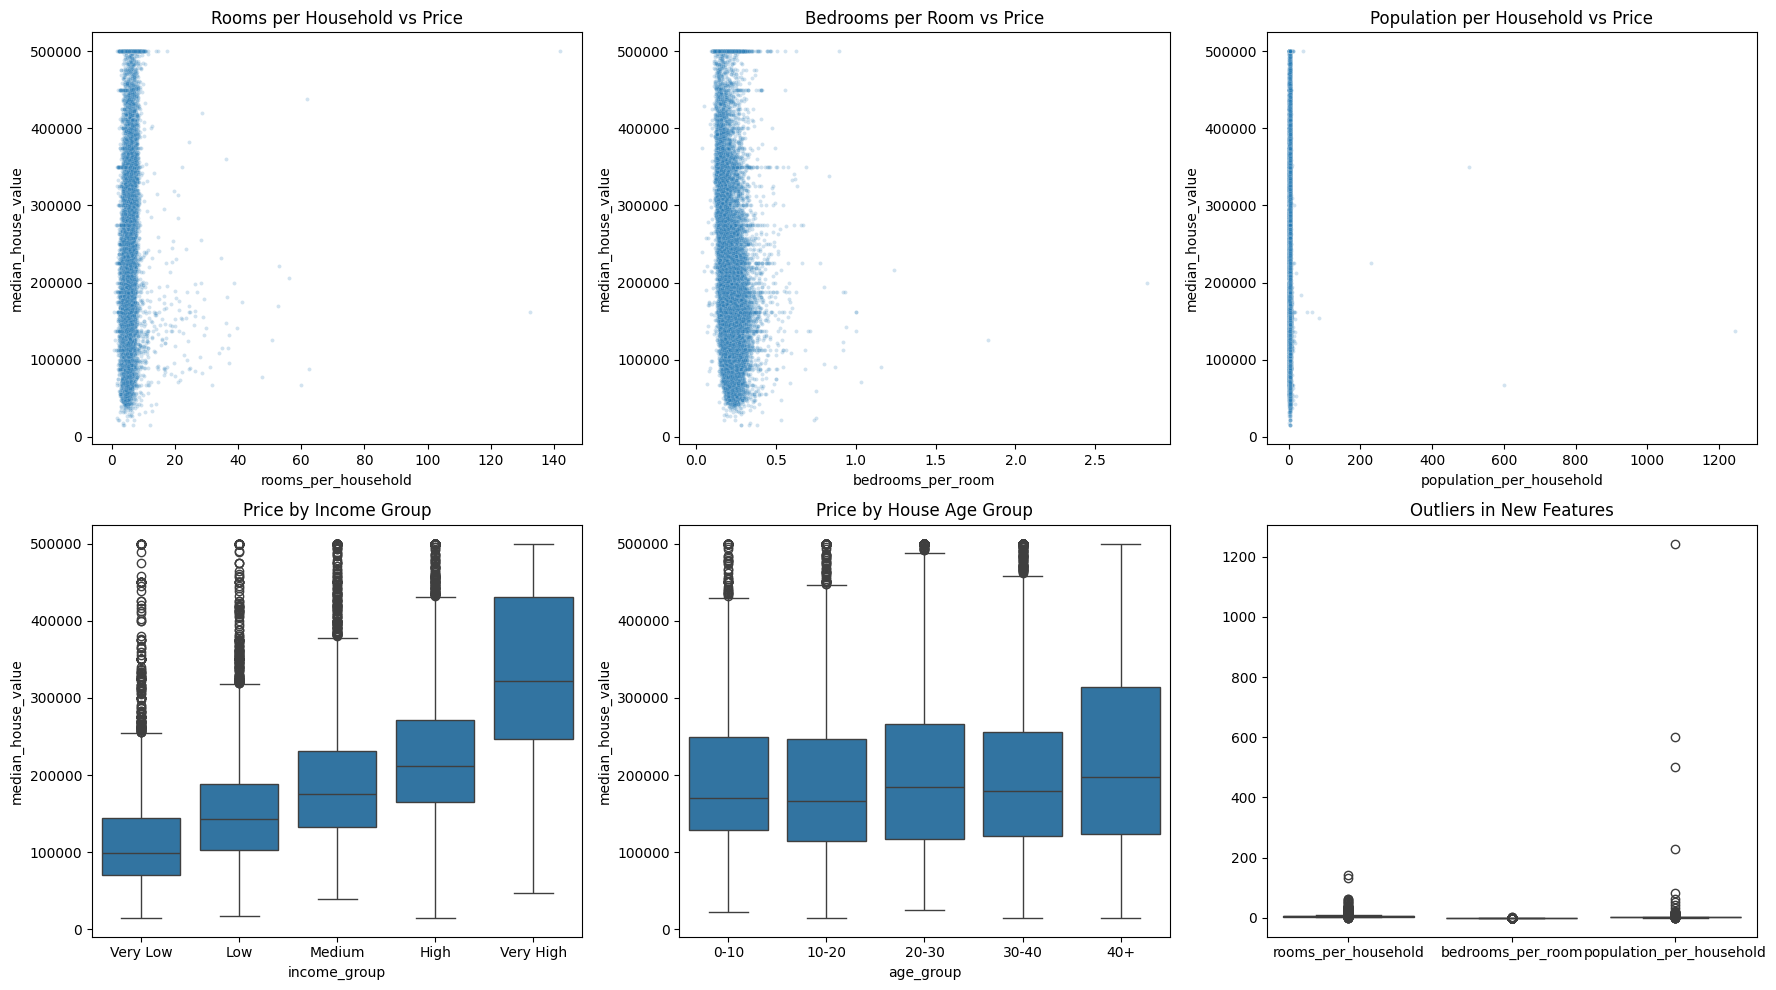

In [4]:
# Temporary engineered features to test whether they help
tmp = df.copy()
tmp['total_bedrooms'] = tmp['total_bedrooms'].fillna(tmp['total_bedrooms'].median())
tmp['rooms_per_household'] = tmp['total_rooms'] / tmp['households']
tmp['bedrooms_per_room'] = tmp['total_bedrooms'] / tmp['total_rooms']
tmp['population_per_household'] = tmp['population'] / tmp['households']

new_cols = ['rooms_per_household', 'bedrooms_per_room', 'population_per_household']
print("Correlation of new features with price:\n", tmp[new_cols + [target]].corr()[target].drop(target).round(3))
print("\nSkewness of key columns:\n", tmp[['median_house_value', 'median_income', 'total_rooms', 'population']].skew().round(2))
print("\nOutlier check (max values):\n", tmp[new_cols].max().round(1))
print("Rows with rooms_per_household > 20:", (tmp['rooms_per_household'] > 20).sum())
print("Rows with population_per_household > 10:", (tmp['population_per_household'] > 10).sum())

tmp['income_group'] = pd.qcut(tmp['median_income'], 5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])
print("\nAverage price by income group:\n", tmp.groupby('income_group', observed=True)[target].mean().round(0))

tmp['age_group'] = pd.cut(tmp['housing_median_age'], [0, 10, 20, 30, 40, 60], labels=['0-10', '10-20', '20-30', '30-40', '40+'])
print("\nAverage price by house age group:\n", tmp.groupby('age_group', observed=True)[target].mean().round(0))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
sns.scatterplot(x='rooms_per_household', y=target, data=tmp, alpha=0.2, s=8, ax=axes[0, 0]); axes[0, 0].set_title('Rooms per Household vs Price')
sns.scatterplot(x='bedrooms_per_room', y=target, data=tmp, alpha=0.2, s=8, ax=axes[0, 1]); axes[0, 1].set_title('Bedrooms per Room vs Price')
sns.scatterplot(x='population_per_household', y=target, data=tmp, alpha=0.2, s=8, ax=axes[0, 2]); axes[0, 2].set_title('Population per Household vs Price')
sns.boxplot(x='income_group', y=target, data=tmp, ax=axes[1, 0]); axes[1, 0].set_title('Price by Income Group')
sns.boxplot(x='age_group', y=target, data=tmp, ax=axes[1, 1]); axes[1, 1].set_title('Price by House Age Group')
sns.boxplot(data=tmp[new_cols], ax=axes[1, 2]); axes[1, 2].set_title('Outliers in New Features')
plt.tight_layout(); plt.show()

In [5]:
# 1. Remove capped prices
before = len(df)
df = df[df['median_house_value'] < 500000].copy()
print("Removed capped-price rows:", before - len(df))

# 2. Fill missing bedrooms with the median
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())

# 3. New features
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
df['population_per_household'] = df['population'] / df['households']

# 4. Remove extreme outliers in the new features
before = len(df)
df = df[(df['rooms_per_household'] < 20) & (df['population_per_household'] < 10)].copy()
print("Removed outlier rows:", before - len(df))

# 5. Encode location category
df = pd.get_dummies(df, columns=['ocean_proximity'], dtype=int)

# 6. Split 80/20
from sklearn.model_selection import train_test_split
X = df.drop(columns='median_house_value')
y = df['median_house_value']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("\nFinal shape:", df.shape)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Missing values left:", df.isnull().sum().sum())
print("Features:", list(X.columns))

Removed capped-price rows: 992
Removed outlier rows: 100

Final shape: (19548, 17)
Train: (15638, 16) | Test: (3910, 16)
Missing values left: 0
Features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


In [8]:
import re

# Remove forbidden characters from column names
df.columns = [re.sub(r'[\[\]<>]', '', c).replace(' ', '_') for c in df.columns]

X = df.drop(columns='median_house_value')
y = df['median_house_value']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Features:", list(X.columns))
print("Train:", X_train.shape, "| Test:", X_test.shape)

Features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'ocean_proximity_1H_OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR_BAY', 'ocean_proximity_NEAR_OCEAN']
Train: (15638, 16) | Test: (3910, 16)


                      R2        MAE       RMSE
Model                                         
Linear Regression  0.648  42934.580  58604.769
Decision Tree      0.678  37853.811  56036.069
XGBoost            0.824  27903.701  41462.617

Best model before tuning: XGBoost


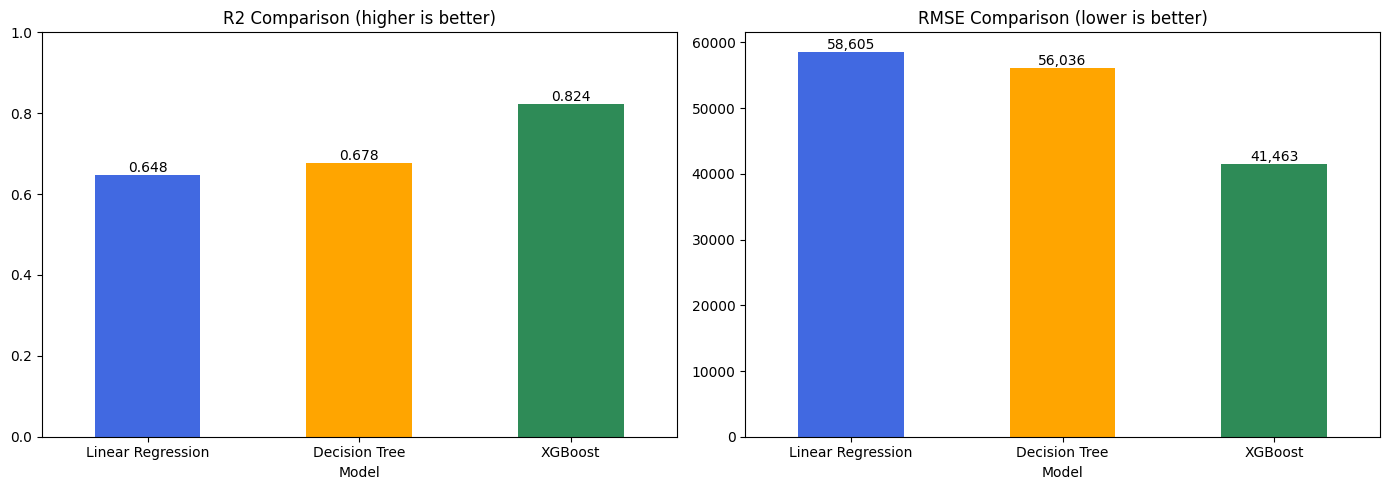

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

models = {
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Decision Tree': DecisionTreeRegressor(max_depth=10, random_state=42),
    'XGBoost': XGBRegressor(random_state=42, n_jobs=-1),
}

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({'Model': name,
                 'R2': r2_score(y_test, p),
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p))})

base = pd.DataFrame(rows).set_index('Model')
print(base.round(3))
print("\nBest model before tuning:", base['R2'].idxmax())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = base['R2'].plot(kind='bar', color=['royalblue', 'orange', 'seagreen'], ylim=(0, 1),
                     title='R2 Comparison (higher is better)', ax=axes[0])
for i, v in enumerate(base['R2']): ax.text(i, v, f"{v:.3f}", ha='center', va='bottom')
ax.tick_params(axis='x', rotation=0)

ax = base['RMSE'].plot(kind='bar', color=['royalblue', 'orange', 'seagreen'],
                       title='RMSE Comparison (lower is better)', ax=axes[1])
for i, v in enumerate(base['RMSE']): ax.text(i, v, f"{v:,.0f}", ha='center', va='bottom')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best parameters: {'subsample': 0.85, 'n_estimators': 400, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.7}

XGBoost R2 before tuning: 0.8236
XGBoost R2 after tuning : 0.8371
MAE before: 27,904
MAE after : 26,297
RMSE before: 41,463
RMSE after : 39,845


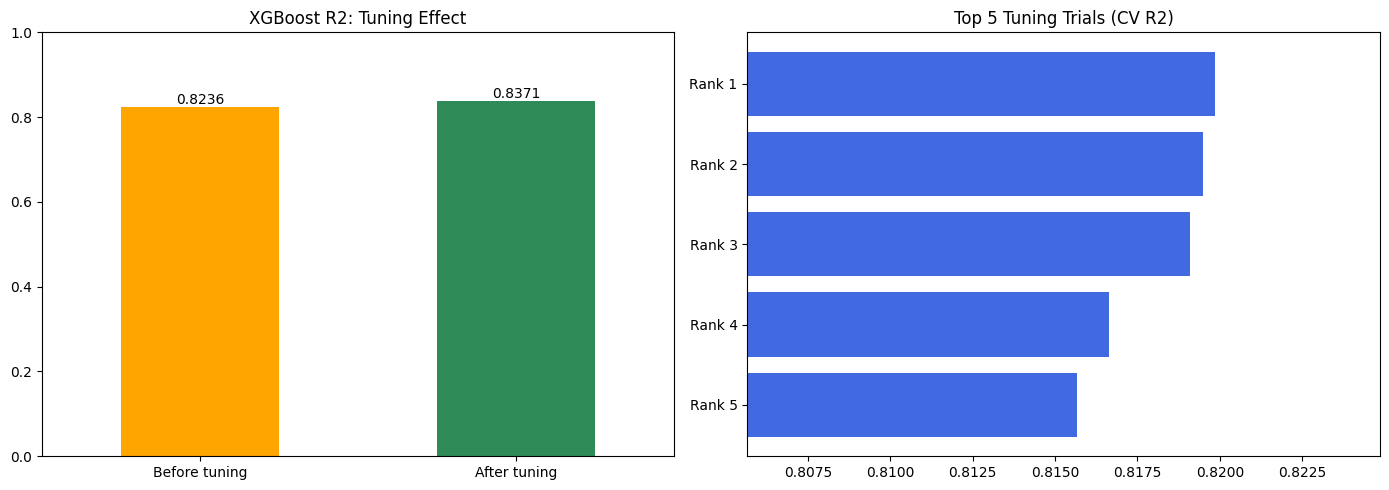

In [10]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [200, 400, 600],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.7, 0.85, 1.0],
    'colsample_bytree': [0.7, 0.85, 1.0],
    'min_child_weight': [1, 3, 5],
}

search = RandomizedSearchCV(XGBRegressor(random_state=42, n_jobs=-1),
                            param_dist, n_iter=15, cv=3, scoring='r2',
                            random_state=42, n_jobs=-1, verbose=1)
search.fit(X_train, y_train)
best_model = search.best_estimator_

print("Best parameters:", search.best_params_)

p_before = models['XGBoost'].predict(X_test)
p_after = best_model.predict(X_test)
print(f"\nXGBoost R2 before tuning: {r2_score(y_test, p_before):.4f}")
print(f"XGBoost R2 after tuning : {r2_score(y_test, p_after):.4f}")
print(f"MAE before: {mean_absolute_error(y_test, p_before):,.0f}")
print(f"MAE after : {mean_absolute_error(y_test, p_after):,.0f}")
print(f"RMSE before: {np.sqrt(mean_squared_error(y_test, p_before)):,.0f}")
print(f"RMSE after : {np.sqrt(mean_squared_error(y_test, p_after)):,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
vals = [r2_score(y_test, p_before), r2_score(y_test, p_after)]
ax = pd.Series(vals, index=['Before tuning', 'After tuning']).plot(
    kind='bar', color=['orange', 'seagreen'], ylim=(0, 1), title='XGBoost R2: Tuning Effect', ax=axes[0])
for i, v in enumerate(vals): ax.text(i, v, f"{v:.4f}", ha='center', va='bottom')
ax.tick_params(axis='x', rotation=0)

cv = pd.DataFrame(search.cv_results_).sort_values('rank_test_score').head(5)
axes[1].barh(range(5), cv['mean_test_score'][::-1], color='royalblue')
axes[1].set_yticks(range(5)); axes[1].set_yticklabels([f"Rank {r}" for r in cv['rank_test_score'][::-1]])
axes[1].set_xlim(cv['mean_test_score'].min() - 0.01, cv['mean_test_score'].max() + 0.005)
axes[1].set_title('Top 5 Tuning Trials (CV R2)')
plt.tight_layout(); plt.show()

Final R2  : 0.8371
Final MAE : $26,297
Final RMSE: $39,845

Median % error: 10.6%
Predictions within 10% of actual: 47.9%
Predictions within 20% of actual: 76.1%

Top 8 important features:
 ocean_proximity_INLAND        0.6053
median_income                 0.0765
ocean_proximity_NEAR_BAY      0.0585
ocean_proximity_ISLAND        0.0391
ocean_proximity_NEAR_OCEAN    0.0354
population_per_household      0.0302
longitude                     0.0279
ocean_proximity_1H_OCEAN      0.0278
dtype: float32


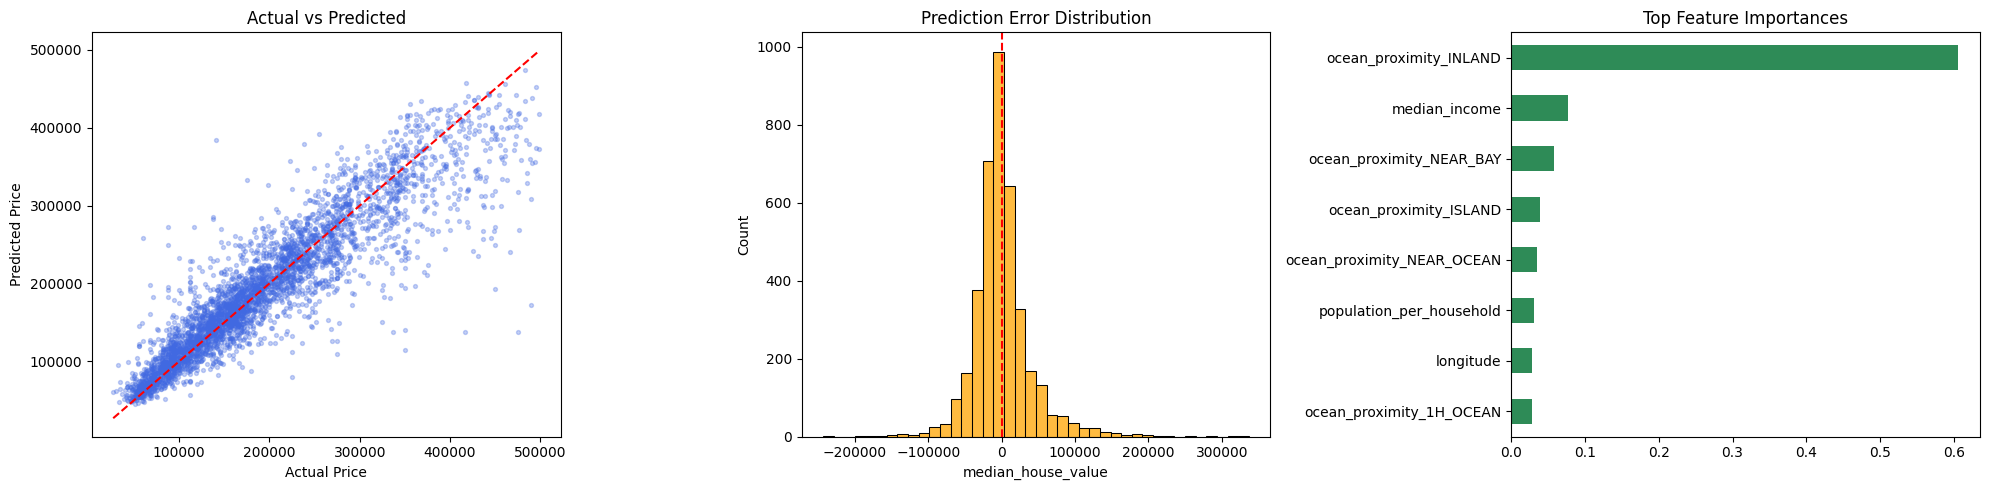

In [11]:
final_pred = best_model.predict(X_test)
print(f"Final R2  : {r2_score(y_test, final_pred):.4f}")
print(f"Final MAE : ${mean_absolute_error(y_test, final_pred):,.0f}")
print(f"Final RMSE: ${np.sqrt(mean_squared_error(y_test, final_pred)):,.0f}")

errors = y_test - final_pred
pct_err = (errors.abs() / y_test * 100)
print(f"\nMedian % error: {pct_err.median():.1f}%")
print(f"Predictions within 10% of actual: {(pct_err <= 10).mean()*100:.1f}%")
print(f"Predictions within 20% of actual: {(pct_err <= 20).mean()*100:.1f}%")

imp = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop 8 important features:\n", imp.head(8).round(4))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].scatter(y_test, final_pred, alpha=0.3, s=8, color='royalblue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0].set_xlabel('Actual Price'); axes[0].set_ylabel('Predicted Price'); axes[0].set_title('Actual vs Predicted')

sns.histplot(errors, bins=40, color='orange', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title('Prediction Error Distribution')

imp.head(8).sort_values().plot(kind='barh', color='seagreen', ax=axes[2], title='Top Feature Importances')

plt.tight_layout(); plt.show()

In [12]:
import ipywidgets as widgets
from IPython.display import display, clear_output

style = {'description_width': '120px'}
w = {
    'median_income': widgets.FloatSlider(value=3.5, min=0.5, max=15, step=0.1, description='Income (10k$)', style=style),
    'housing_median_age': widgets.IntSlider(value=28, min=1, max=52, description='House age', style=style),
    'total_rooms': widgets.IntSlider(value=2000, min=100, max=10000, step=50, description='Total rooms', style=style),
    'total_bedrooms': widgets.IntSlider(value=400, min=50, max=2000, step=10, description='Bedrooms', style=style),
    'population': widgets.IntSlider(value=1200, min=100, max=5000, step=50, description='Population', style=style),
    'households': widgets.IntSlider(value=400, min=50, max=2000, step=10, description='Households', style=style),
    'latitude': widgets.FloatSlider(value=34.2, min=32.5, max=42, step=0.1, description='Latitude', style=style),
    'longitude': widgets.FloatSlider(value=-118.5, min=-124.3, max=-114.3, step=0.1, description='Longitude', style=style),
}
ocean = widgets.Dropdown(
    options=['1H_OCEAN', 'INLAND', 'NEAR_BAY', 'NEAR_OCEAN', 'ISLAND'],
    value='1H_OCEAN', description='Location', style=style)
btn = widgets.Button(description='Predict Price', button_style='success')
out = widgets.Output()

def on_click(_):
    row = {c: 0 for c in X.columns}
    for k, v in w.items():
        row[k] = v.value
    row['rooms_per_household'] = row['total_rooms'] / row['households']
    row['bedrooms_per_room'] = row['total_bedrooms'] / row['total_rooms']
    row['population_per_household'] = row['population'] / row['households']
    row['ocean_proximity_' + ocean.value] = 1
    price = best_model.predict(pd.DataFrame([row])[X.columns])[0]
    with out:
        clear_output()
        print(f"Predicted House Price: ${price:,.0f}")

btn.on_click(on_click)
display(*w.values(), ocean, btn, out)

FloatSlider(value=3.5, description='Income (10k$)', max=15.0, min=0.5, style=SliderStyle(description_width='12…

IntSlider(value=28, description='House age', max=52, min=1, style=SliderStyle(description_width='120px'))

IntSlider(value=2000, description='Total rooms', max=10000, min=100, step=50, style=SliderStyle(description_wi…

IntSlider(value=400, description='Bedrooms', max=2000, min=50, step=10, style=SliderStyle(description_width='1…

IntSlider(value=1200, description='Population', max=5000, min=100, step=50, style=SliderStyle(description_widt…

IntSlider(value=400, description='Households', max=2000, min=50, step=10, style=SliderStyle(description_width=…

FloatSlider(value=34.2, description='Latitude', max=42.0, min=32.5, style=SliderStyle(description_width='120px…

FloatSlider(value=-118.5, description='Longitude', max=-114.3, min=-124.3, style=SliderStyle(description_width…

Dropdown(description='Location', options=('1H_OCEAN', 'INLAND', 'NEAR_BAY', 'NEAR_OCEAN', 'ISLAND'), style=Des…

Button(button_style='success', description='Predict Price', style=ButtonStyle())

Output()